<a href="https://colab.research.google.com/github/DanielBerns/python_para_universitarios/blob/main/check_spreadsheet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

class CheckSpreadsheet:
    def __init__(self):
        self.df = None
        self.file_path = None

    def load_data(self, file_path):
        """
        Opens a spreadsheet. Supports CSV, TSV, JSON, and Excel formats.
        """
        self.file_path = file_path
        _, ext = os.path.splitext(file_path)
        ext = ext.lower()

        try:
            if ext == '.csv':
                self.df = pd.read_csv(file_path)
            elif ext == '.tsv':
                self.df = pd.read_csv(file_path, sep='\t')
            elif ext == '.json':
                self.df = pd.read_json(file_path)
            elif ext in ['.xls', '.xlsx', '.odf', '.ods', '.odt']:
                self.df = pd.read_excel(file_path)
            else:
                raise ValueError(f"Unsupported file extension: {ext}")
            print(f"Successfully loaded: {file_path}")
            self.show_dimensions()
        except Exception as e:
            print(f"Error loading file: {e}")
            self.df = None

    def show_dimensions(self):
        """
        Displays the number of rows and columns in the dataset.
        """
        if self.df is None:
            print("No data loaded yet. Please run load_data() first.")
            return
        rows, cols = self.df.shape
        print(f"Dimensions: {rows} rows, {cols} columns")

    def common_stats(self):
        """
        Prints common statistical metrics for numeric and categorical columns.
        """
        if self.df is None:
            print("No data loaded.")
            return
        print("--- Common Statistics (Numeric Columns) ---")
        display(self.df.describe())

        # Optional display for non-numeric columns if present
        non_numeric = self.df.select_dtypes(exclude=['number'])
        if not non_numeric.empty:
            print("\n--- Common Statistics (Categorical/Other Columns) ---")
            display(non_numeric.describe())

    def test_nans(self):
        """
        Tests for and summarizes missing values (NaNs) in the dataset.
        """
        if self.df is None:
            print("No data loaded.")
            return
        nan_counts = self.df.isna().sum()
        nan_percentage = (nan_counts / len(self.df)) * 100

        nan_df = pd.DataFrame({
            'Missing Values': nan_counts,
            'Percentage (%)': nan_percentage
        })

        print("--- Missing Values (NaNs) Report ---")
        display(nan_df[nan_df['Missing Values'] > 0] if nan_counts.sum() > 0 else "No missing values found.")

    def show_histograms(self, columns=None, bins=10):
        """
        Plots histograms for numeric columns automatically if none are specified.
        """
        if self.df is None:
            print("No data loaded.")
            return

        numeric_cols = self.df.select_dtypes(include=['number']).columns
        if columns:
            cols_to_plot = [c for c in columns if c in numeric_cols]
        else:
            cols_to_plot = list(numeric_cols)

        if not cols_to_plot:
            print("No numeric columns available to plot histograms.")
            return

        for col in cols_to_plot:
            plt.figure(figsize=(8, 4))
            sns.histplot(self.df[col].dropna(), bins=bins, kde=True)
            plt.title(f'Histogram of {col}')
            plt.xlabel(col)
            plt.ylabel('Frequency')
            plt.show()

    def make_plot(self, x_col=None, y_col=None, plot_type='scatter'):
        """
        Generates a custom plot (scatter, line, or boxplot).
        If x_col and y_col are not specified, it automatically plots first two numeric columns.
        """
        if self.df is None:
            print("No data loaded.")
            return

        numeric_cols = list(self.df.select_dtypes(include=['number']).columns)

        if x_col is None or y_col is None:
            if len(numeric_cols) >= 2:
                x_col = numeric_cols[0]
                y_col = numeric_cols[1]
                print(f"Automatically selected numeric columns for plotting: '{x_col}' and '{y_col}'")
            elif len(numeric_cols) == 1:
                print("Only one numeric column found, displaying plot against index.")
                x_col = self.df.index.name or 'index'
                self.df[x_col] = self.df.index
                y_col = numeric_cols[0]
            else:
                print("No numeric columns found to generate comparison plots.")
                return

        if x_col not in self.df.columns or y_col not in self.df.columns:
            print(f"One or both specified columns ({x_col}, {y_col}) do not exist in the dataset.")
            return

        plt.figure(figsize=(10, 6))
        if plot_type == 'scatter':
            sns.scatterplot(data=self.df, x=x_col, y=y_col)
        elif plot_type == 'line':
            sns.lineplot(data=self.df, x=x_col, y=y_col)
        elif plot_type == 'box':
            sns.boxplot(data=self.df, x=x_col, y=y_col)
        else:
            print(f"Unsupported plot type: {plot_type}. Choose 'scatter', 'line', or 'box'.")
            return

        plt.title(f'{plot_type.capitalize()} Plot: {x_col} vs {y_col}')
        plt.show()

Successfully loaded: /content/sample_data/california_housing_test.csv
Dimensions: 3000 rows, 9 columns
--- Common Statistics (Numeric Columns) ---


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,3000.000000,3000.00000,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000,3000.00000
mean,-119.589200,35.63539,28.845333,2599.578667,529.950667,1402.798667,489.91200,3.807272,205846.27500
std,1.994936,2.12967,12.555396,2155.593332,415.654368,1030.543012,365.42271,1.854512,113119.68747
min,-124.180000,32.56000,1.000000,6.000000,2.000000,5.000000,2.00000,0.499900,22500.00000
25%,-121.810000,33.93000,18.000000,1401.000000,291.000000,780.000000,273.00000,2.544000,121200.00000
50%,-118.485000,34.27000,29.000000,2106.000000,437.000000,1155.000000,409.50000,3.487150,177650.00000
75%,-118.020000,37.69000,37.000000,3129.000000,636.000000,1742.750000,597.25000,4.656475,263975.00000
max,-114.490000,41.92000,52.000000,30450.000000,5419.000000,11935.000000,4930.00000,15.000100,500001.00000


--- Missing Values (NaNs) Report ---


'No missing values found.'

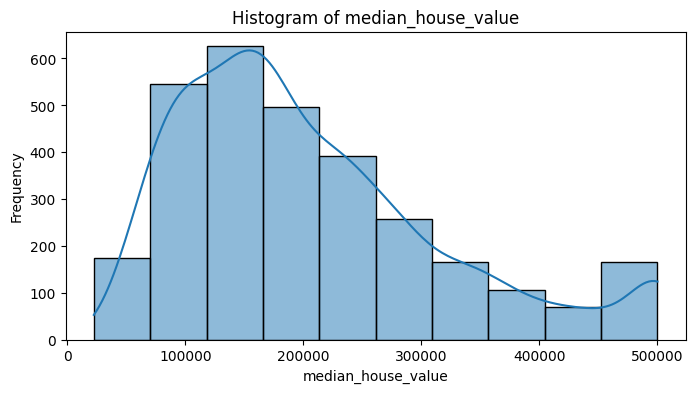

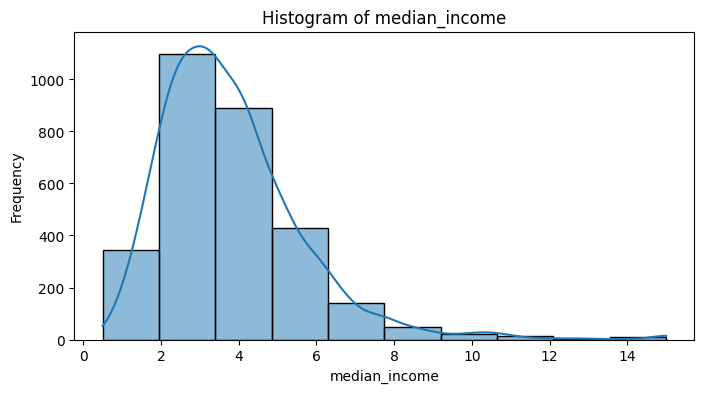

Automatically selected numeric columns for plotting: 'longitude' and 'latitude'


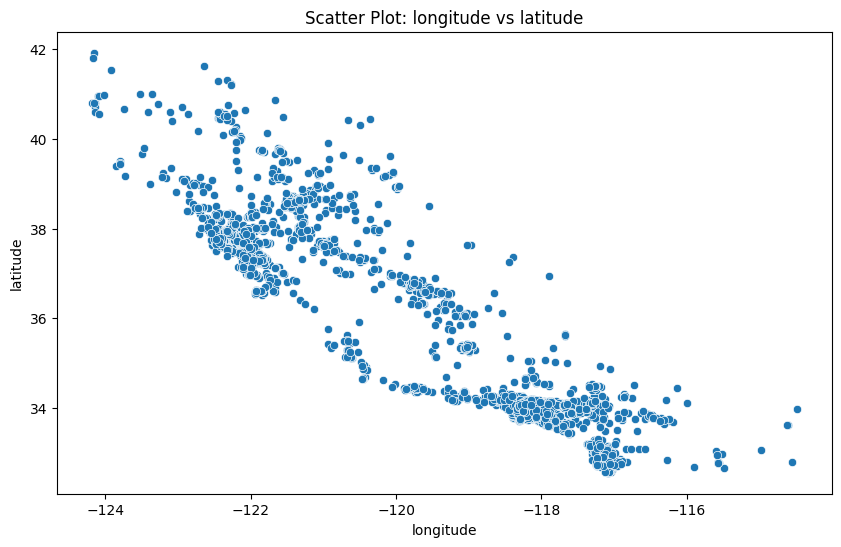

In [3]:
# Instantiate the class and test it with a sample Colab dataset
checker = CheckSpreadsheet()

# 1. Load data
checker.load_data('/content/sample_data/california_housing_test.csv')

# 2. Show common stats
checker.common_stats()

# 3. Test for NaNs
checker.test_nans()

# 4. Show histograms (automatically handling numeric columns)
checker.show_histograms(columns=['median_house_value', 'median_income'])

# 5. Make a custom plot (automatically selecting first two columns if none are passed)
checker.make_plot(plot_type='scatter')